In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Load data
coaches = pd.read_csv("../basketballPlayoffs/coaches.csv")

# Win percentage columns
coaches['win_pct'] = coaches['won'] / (coaches['won'] + coaches['lost'])
coaches['post_win_pct'] = coaches['post_wins'] / (coaches['post_wins'] + coaches['post_losses'])

# Top regular season coaches by win percentage
top_coaches_regular = coaches.groupby('coachID')['win_pct'].mean().sort_values(ascending=False).head(10)
print("Top 10 Coaches by Regular Season Win Percentage:")
print(top_coaches_regular)
print()

# Top postseason coaches by win percentage
top_coaches_post = coaches.groupby('coachID')['post_win_pct'].mean().sort_values(ascending=False).head(10)
print("Top 10 Coaches by Postseason Win Percentage:")
print(top_coaches_post)



Top 10 Coaches by Regular Season Win Percentage:
coachID
weisery99w    0.785714
bryanjo01w    0.700980
coopemi01w    0.668612
millech99w    0.625000
whisejo99w    0.612185
chancva99w    0.606618
westhpa99w    0.602941
thibami99w    0.600840
allenso99w    0.578125
wintebr01w    0.573529
Name: win_pct, dtype: float64

Top 10 Coaches by Postseason Win Percentage:
coachID
westhpa99w    0.777778
coopemi01w    0.652116
gaineco01w    0.636364
whisejo99w    0.635417
stanlma99w    0.600000
mchugma99w    0.600000
mahorri01w    0.600000
laimbbi01w    0.517761
thibami99w    0.502778
adubari99w    0.392857
Name: post_win_pct, dtype: float64


In [38]:
# Calculate total wins, losses, post wins, and post losses for each coach
coach_stats = coaches.groupby('coachID').agg(
    total_wins=('won', 'sum'),
    total_post_wins=('post_wins', 'sum'),
    total_losses=('lost', 'sum'),
    total_post_losses=('post_losses', 'sum')
).reset_index()

# Calculate win percentage and postseason win percentage
coach_stats['win_pct'] = coach_stats['total_wins'] / (coach_stats['total_wins'] + coach_stats['total_losses'])
coach_stats['post_win_pct'] = coach_stats['total_post_wins'] / (coach_stats['total_post_wins'] + coach_stats['total_post_losses'])

# Reorder columns as specified
coach_stats = coach_stats[['coachID', 'total_wins', 'total_losses', 'win_pct', 'total_post_wins', 'total_post_losses', 'post_win_pct']]

# Sort the results by total_wins in descending order
coach_stats_sorted = coach_stats.sort_values(by='total_wins', ascending=False).reset_index()

# Display the result
print(coach_stats_sorted)

    index     coachID  total_wins  total_losses   win_pct  total_post_wins  \
0      11  coopemi01w         167            85  0.662698               25   
1      25  hugheda99w         145           155  0.483333               12   
2      16  donovan99w         145           138  0.512367               12   
3      46  thibami99w         143            95  0.600840               17   
4       9  chancva99w         140            92  0.603448               10   
5      30  laimbbi01w         137            92  0.598253               27   
6       1  adubari99w         116           102  0.532110               11   
7      52  whisejo99w          85            54  0.611511               19   
8      13  coylepa99w          81            90  0.473684                6   
9      55  wintebr01w          78            58  0.573529                5   
10      2  aglerbr99w          75            76  0.496689                2   
11     17  dunnli99wc          72            92  0.439024       

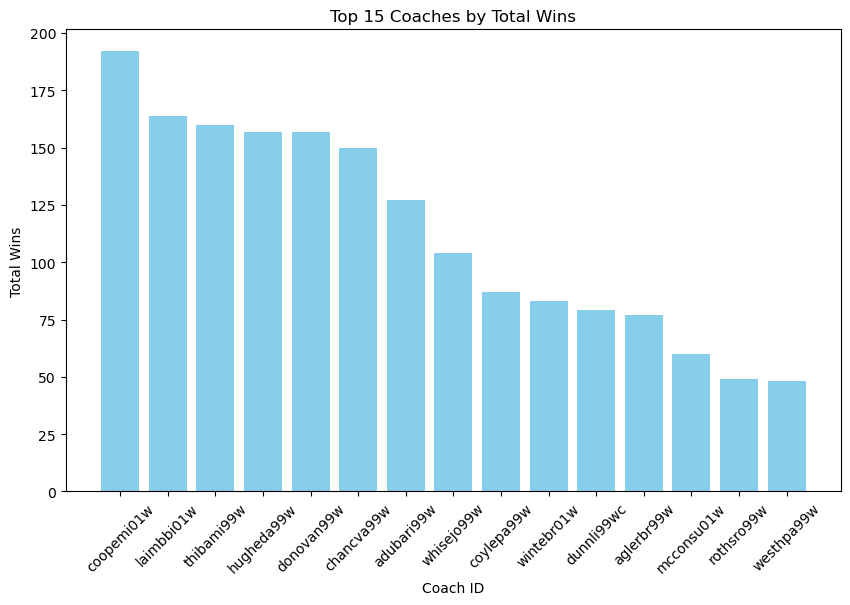

In [74]:
# Sort and select top 15 coaches by total wins
coach_stats['total_games_wins'] = coach_stats['total_wins'] + coach_stats['total_post_wins']
top15_wins = coach_stats.sort_values(by='total_games_wins', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.bar(top15_wins['coachID'], top15_wins['total_games_wins'], color='skyblue')
plt.xlabel("Coach ID")
plt.ylabel("Total Wins")
plt.title("Top 15 Coaches by Total Wins")
plt.xticks(rotation=45)
plt.show()


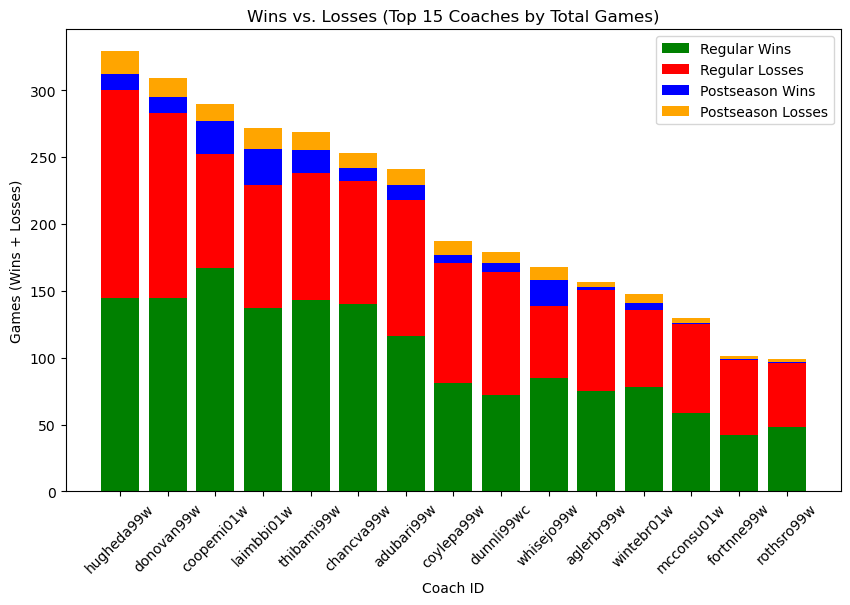

In [75]:
# Sort and select top 15 coaches by total games
coach_stats['total_games'] = coach_stats['total_wins'] + coach_stats['total_losses'] + coach_stats['total_post_wins'] + coach_stats['total_post_losses']
top15_games = coach_stats.sort_values(by='total_games', ascending=False).head(15)

# Stacked Bar Plot of Wins vs. Losses for Top 15 Coaches by Total Games
plt.figure(figsize=(10, 6))
bar1 = plt.bar(top15_games['coachID'], top15_games['total_wins'], color='green')
bar2 = plt.bar(top15_games['coachID'], top15_games['total_losses'], bottom=top15_games['total_wins'], color='red')
bar3 = plt.bar(top15_games['coachID'], top15_games['total_post_wins'], bottom=top15_games['total_losses'] + top15_games['total_wins'], color='blue')
bar4 = plt.bar(top15_games['coachID'], top15_games['total_post_losses'], bottom=top15_games['total_losses'] + top15_games['total_wins'] + top15_games['total_post_wins'], color='orange')
plt.xlabel("Coach ID")
plt.ylabel("Games (Wins + Losses)")
plt.title("Wins vs. Losses (Top 15 Coaches by Total Games)")
plt.xticks(rotation=45)
plt.legend((bar1, bar2, bar3, bar4), ('Regular Wins', 'Regular Losses', 'Postseason Wins', 'Postseason Losses'))
plt.show()


In [ ]:
# fazer plot que associe coaches e win percentage